# 03 — Attention and a Full Transformer Block, From Scratch

**Overview:** scaled dot-product attention (Q/K/V, multi-head, causal masking), then a
complete Transformer block: embeddings + positional encoding + multi-head self-attention +
residual connections + LayerNorm + feed-forward network.

**Required libraries:** `numpy`, `matplotlib`.

Connects to: `02_rnn_lstm_gru_concept.ipynb` (attention replaces step-by-step sequence
processing) and `16_backpropagation` (residual connections exist specifically to help
gradients flow). Leads directly to `llm-fine-tuning/`'s curriculum in this workspace, and to
`20_pytorch_models` for PyTorch's built-in attention modules.

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)


## 1. Scaled dot-product attention, from scratch

**Equation:** `Attention(Q,K,V) = softmax(QKᵗ / √d_k) V`

💡 **Intuition:** for each query position, compute a similarity score against every key
position (`QKᵗ`), turn those scores into a probability distribution (softmax), then take a
weighted average of the value vectors using that distribution.

In [2]:
def softmax(z, axis=-1):
    z_shifted = z - np.max(z, axis=axis, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=axis, keepdims=True)

def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]
    scores = Q @ K.swapaxes(-2, -1) / np.sqrt(d_k)   # (..., seq_len_q, seq_len_k)
    if mask is not None:
        scores = np.where(mask, scores, -np.inf)
    attention_weights = softmax(scores, axis=-1)
    output = attention_weights @ V
    return output, attention_weights

seq_len, d_k, d_v = 5, 8, 8
Q = rng.normal(size=(seq_len, d_k))
K = rng.normal(size=(seq_len, d_k))
V = rng.normal(size=(seq_len, d_v))

output, weights = scaled_dot_product_attention(Q, K, V)
print("output shape:", output.shape, "== (seq_len, d_v) =", (seq_len, d_v))
print("attention weights shape:", weights.shape, "== (seq_len_q, seq_len_k) =", (seq_len, seq_len))
print("\neach row of attention weights sums to 1:", weights.sum(axis=-1).round(6))

assert output.shape == (seq_len, d_v)
assert np.allclose(weights.sum(axis=-1), 1.0)


output shape: (5, 8) == (seq_len, d_v) = (5, 8)
attention weights shape: (5, 5) == (seq_len_q, seq_len_k) = (5, 5)

each row of attention weights sums to 1: [1. 1. 1. 1. 1.]


## 2. Why scale by √d_k?

⚠️ **Common Mistake:** forgetting the `/√d_k` scaling -- without it, dot products grow with
`d_k`, pushing softmax into a very peaked, low-gradient regime.

In [3]:
large_d_k = 512
Q_large = rng.normal(size=(seq_len, large_d_k))
K_large = rng.normal(size=(seq_len, large_d_k))

unscaled_scores = Q_large @ K_large.T                       # no scaling
scaled_scores = unscaled_scores / np.sqrt(large_d_k)         # with scaling

print("unscaled scores std:", unscaled_scores.std().round(2))
print("scaled scores std:  ", scaled_scores.std().round(2), "(much closer to 1, as intended)")

unscaled_weights = softmax(unscaled_scores)
scaled_weights = softmax(scaled_scores)
print("\nmax attention weight, unscaled (often near 1.0, i.e. nearly one-hot):", unscaled_weights.max().round(4))
print("max attention weight, scaled   (more spread out):                      ", scaled_weights.max().round(4))

assert scaled_scores.std() < unscaled_scores.std()


unscaled scores std: 23.36
scaled scores std:   1.03 (much closer to 1, as intended)

max attention weight, unscaled (often near 1.0, i.e. nearly one-hot): 1.0
max attention weight, scaled   (more spread out):                       0.598


## 3. Multi-head attention

💡 **Intuition:** split Q/K/V into several smaller "heads," run attention independently per
head (each can learn a different kind of relationship), then concatenate and project the
results back to the original dimension.

In [4]:
def multi_head_attention(X, num_heads, W_q, W_k, W_v, W_o):
    seq_len, d_model = X.shape
    d_head = d_model // num_heads

    Q = X @ W_q   # (seq_len, d_model)
    K = X @ W_k
    V = X @ W_v

    # Split into heads: (seq_len, d_model) -> (num_heads, seq_len, d_head)
    def split_heads(M):
        return M.reshape(seq_len, num_heads, d_head).transpose(1, 0, 2)

    Qh, Kh, Vh = split_heads(Q), split_heads(K), split_heads(V)
    head_outputs, _ = scaled_dot_product_attention(Qh, Kh, Vh)   # (num_heads, seq_len, d_head)

    # Concatenate heads back: (num_heads, seq_len, d_head) -> (seq_len, d_model)
    concatenated = head_outputs.transpose(1, 0, 2).reshape(seq_len, d_model)
    return concatenated @ W_o

d_model, num_heads = 16, 4
X = rng.normal(scale=0.3, size=(seq_len, d_model))
W_q = rng.normal(scale=0.2, size=(d_model, d_model))
W_k = rng.normal(scale=0.2, size=(d_model, d_model))
W_v = rng.normal(scale=0.2, size=(d_model, d_model))
W_o = rng.normal(scale=0.2, size=(d_model, d_model))

mha_output = multi_head_attention(X, num_heads, W_q, W_k, W_v, W_o)
print("multi-head attention output shape:", mha_output.shape, "== input shape:", X.shape)
assert mha_output.shape == X.shape   # attention preserves shape, so blocks can stack


multi-head attention output shape: (5, 16) == input shape: (5, 16)


## 4. Causal masking

💡 **Intuition:** a decoder generating text one token at a time must not be able to attend to
positions it hasn't generated yet -- the causal mask enforces this during training by zeroing
out (via -inf before softmax) all "future" positions.

causal mask (True = can attend, False = masked out):
 [[ True False False False False]
 [ True  True False False False]
 [ True  True  True False False]
 [ True  True  True  True False]
 [ True  True  True  True  True]]

attention weights WITH causal mask:
 [[1.    0.    0.    0.    0.   ]
 [0.416 0.584 0.    0.    0.   ]
 [0.371 0.427 0.202 0.    0.   ]
 [0.483 0.195 0.208 0.114 0.   ]
 [0.116 0.295 0.231 0.132 0.225]]

verified: no position attends to any future position.


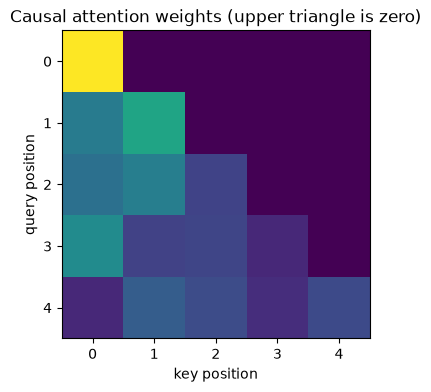

In [5]:
def causal_mask(seq_len):
    return np.tril(np.ones((seq_len, seq_len), dtype=bool))   # lower triangle (including diagonal) = allowed

mask = causal_mask(seq_len)
print("causal mask (True = can attend, False = masked out):\n", mask)

_, causal_weights = scaled_dot_product_attention(Q, K, V, mask=mask)
print("\nattention weights WITH causal mask:\n", causal_weights.round(3))

# Position i should have exactly zero attention weight on any position j > i.
for i in range(seq_len):
    for j in range(seq_len):
        if j > i:
            assert causal_weights[i, j] < 1e-9
print("\nverified: no position attends to any future position.")

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(causal_weights, cmap="viridis")
ax.set_title("Causal attention weights (upper triangle is zero)")
ax.set_xlabel("key position"); ax.set_ylabel("query position")
plt.show()


## 5. A full Transformer block

**Equations:**
```
x = embeddings + positional_encoding
attn_out = MultiHeadAttention(x)
x = LayerNorm(x + attn_out)            # residual connection, then normalize
ffn_out = FFN(x)                        # two linear layers with a non-linearity between
x = LayerNorm(x + ffn_out)              # residual connection, then normalize
```

💡 **Intuition:** residual connections (`x + f(x)`) let gradients flow directly through the
block even if `f(x)`'s gradient is small -- critical for training a deep stack of these
blocks without vanishing gradients, the exact problem from the previous notebook.

In [6]:
def positional_encoding(seq_len, d_model):
    position = np.arange(seq_len)[:, None]
    dim = np.arange(d_model)[None, :]
    angle_rates = 1 / np.power(10000, (2 * (dim // 2)) / d_model)
    angles = position * angle_rates
    pe = np.zeros((seq_len, d_model))
    pe[:, 0::2] = np.sin(angles[:, 0::2])
    pe[:, 1::2] = np.cos(angles[:, 1::2])
    return pe

def layer_norm(x, eps=1e-5):
    mean = x.mean(axis=-1, keepdims=True)
    var = x.var(axis=-1, keepdims=True)
    return (x - mean) / np.sqrt(var + eps)

def feed_forward(x, W1, b1, W2, b2):
    hidden = np.maximum(0, x @ W1 + b1)   # ReLU
    return hidden @ W2 + b2

def transformer_block(token_embeddings, mha_weights, ffn_weights):
    seq_len, d_model = token_embeddings.shape
    pe = positional_encoding(seq_len, d_model)
    x = token_embeddings + pe

    attn_out = multi_head_attention(x, num_heads, *mha_weights)
    x = layer_norm(x + attn_out)   # residual + norm

    ffn_out = feed_forward(x, *ffn_weights)
    x = layer_norm(x + ffn_out)    # residual + norm
    return x

d_ff = 32
ffn_weights = (
    rng.normal(scale=0.2, size=(d_model, d_ff)), np.zeros(d_ff),
    rng.normal(scale=0.2, size=(d_ff, d_model)), np.zeros(d_model),
)
mha_weights = (W_q, W_k, W_v, W_o)

token_embeddings = rng.normal(scale=0.3, size=(seq_len, d_model))
block_output = transformer_block(token_embeddings, mha_weights, ffn_weights)

print("transformer block input shape: ", token_embeddings.shape)
print("transformer block output shape:", block_output.shape)
assert block_output.shape == token_embeddings.shape   # shape-preserving, so blocks can stack

# Stack two blocks to confirm they compose.
block_output_2 = transformer_block(block_output, mha_weights, ffn_weights)
print("\nafter stacking a second block, shape is still:", block_output_2.shape)
assert block_output_2.shape == token_embeddings.shape


transformer block input shape:  (5, 16)
transformer block output shape: (5, 16)

after stacking a second block, shape is still: (5, 16)


## 6. Connection to what's next

A decoder-only language model (GPT-style) is a stack of exactly these blocks, with a causal
mask applied inside every attention computation. Day 3's PyTorch sequence
(`18_pytorch_basics` → `22_pytorch_training`) builds and trains a real (if small) network
using PyTorch's `nn.Module`/`nn.MultiheadAttention` instead of these from-scratch NumPy
functions — and this workspace's `llm-fine-tuning/` curriculum picks up directly from here.

## 7. Interview questions
1. Why is attention's output shape the same as its input shape, and why does that matter for stacking blocks?
2. Walk through why scaling by `√d_k` prevents softmax from becoming too peaked.
3. What's the purpose of residual connections in a deep Transformer stack?
4. Why does a decoder need causal masking but an encoder typically doesn't?
5. Why is positional encoding necessary, given self-attention alone has no notion of sequence order?

## 8. Exercises
1. Implement cross-attention (queries from one sequence, keys/values from another) and verify its output shape matches the query sequence's length, not the key/value sequence's length.
2. Visualize attention weights for a few different hand-constructed Q/K vectors and interpret which positions attend most strongly to which.
3. Stack 4 Transformer blocks and verify the output shape is preserved through all of them.

## 9. Summary

✅ Self-attention computes every pairwise relationship in a sequence in one parallelizable
step; multi-head attention runs several such computations in parallel; residual connections +
normalization make deep stacks trainable; causal masking enforces autoregressive generation.
This closes `17_deep_learning_architectures` — next: `18_pytorch_basics`.